In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

import warnings
warnings.filterwarnings('ignore')


In [10]:
df = pd.read_csv('../dataset/iris.csv')

print(f"Dimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
df.head()


Dimensi dataset: 150 baris, 5 kolom



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
# Informasi dataset dan pengecekan missing value
print("Informasi Dataset:")
df.info()

print("\nJumlah Missing Values:")
print(df.isnull().sum())

print("\nDistribusi Label Asli (Species):")
print(df['species'].value_counts())


Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB

Jumlah Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Distribusi Label Asli (Species):
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
# Memisahkan fitur dan target asli
feature_cols = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
X = df[feature_cols]
y_true = df['species']

# Standarisasi fitur agar memiliki mean = 0 dan varians = 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Fitur yang digunakan:", feature_cols)
print("Bentuk matriks fitur setelah standarisasi:", X_scaled.shape)


Fitur yang digunakan: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Bentuk matriks fitur setelah standarisasi: (150, 4)


In [5]:
# Inisialisasi dan fitting model HDBSCAN
# min_cluster_size=5 merupakan nilai default yang umum untuk dataset berukuran kecil
hdb = HDBSCAN(min_cluster_size=5, copy=True)
cluster_labels = hdb.fit_predict(X_scaled)

# Menyimpan hasil ke DataFrame
df['Cluster'] = cluster_labels

# Evaluasi jumlah cluster dan noise
unique_labels = set(cluster_labels)
n_noise = np.sum(cluster_labels == -1)
n_clusters = len(unique_labels - {-1})

print("="*45)
print("HASIL CLUSTERING HDBSCAN")
print("="*45)
print(f"Jumlah cluster terbentuk : {n_clusters}")
print(f"Banyaknya noise (-1)     : {n_noise} sampel")
print("="*45)
print("\nDistribusi sampel per cluster:")
print(pd.Series(cluster_labels).value_counts().sort_index())


HASIL CLUSTERING HDBSCAN
Jumlah cluster terbentuk : 2
Banyaknya noise (-1)     : 2 sampel

Distribusi sampel per cluster:
-1     2
 0    50
 1    98
Name: count, dtype: int64


In [6]:
# Tabel kontingensi: Perbandingan Label Asli vs Cluster HDBSCAN
contingency = pd.crosstab(
    df['species'], 
    df['Cluster'], 
    rownames=['Label Asli (Species)'], 
    colnames=['Cluster HDBSCAN']
)
print("Tabel Kontingensi (Cross-Tabulation):")
print(contingency)

# Evaluasi metrik kesamaan cluster dengan ground truth
ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"\nAdjusted Rand Index (ARI)       : {ari:.4f}")
print(f"Normalized Mutual Info (NMI)    : {nmi:.4f}")


Tabel Kontingensi (Cross-Tabulation):
Cluster HDBSCAN       -1   0   1
Label Asli (Species)            
setosa                 0  50   0
versicolor             0   0  50
virginica              2   0  48

Adjusted Rand Index (ARI)       : 0.5638
Normalized Mutual Info (NMI)    : 0.7175


In [7]:
# Reduksi dimensi menggunakan PCA (2D dan 3D) untuk visualisasi
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_scaled)

df['PCA1'] = X_pca_2d[:, 0]
df['PCA2'] = X_pca_2d[:, 1]
df['PCA3'] = X_pca_3d[:, 2]

print("Rasio Varians Terjelaskan (PCA 2D):", pca_2d.explained_variance_ratio_)
print(f"Total Varians Terjelaskan (PCA 2D): {pca_2d.explained_variance_ratio_.sum()*100:.2f}%")
print(f"Total Varians Terjelaskan (PCA 3D): {pca_3d.explained_variance_ratio_.sum()*100:.2f}%")


Rasio Varians Terjelaskan (PCA 2D): [0.72962445 0.22850762]
Total Varians Terjelaskan (PCA 2D): 95.81%
Total Varians Terjelaskan (PCA 3D): 99.48%


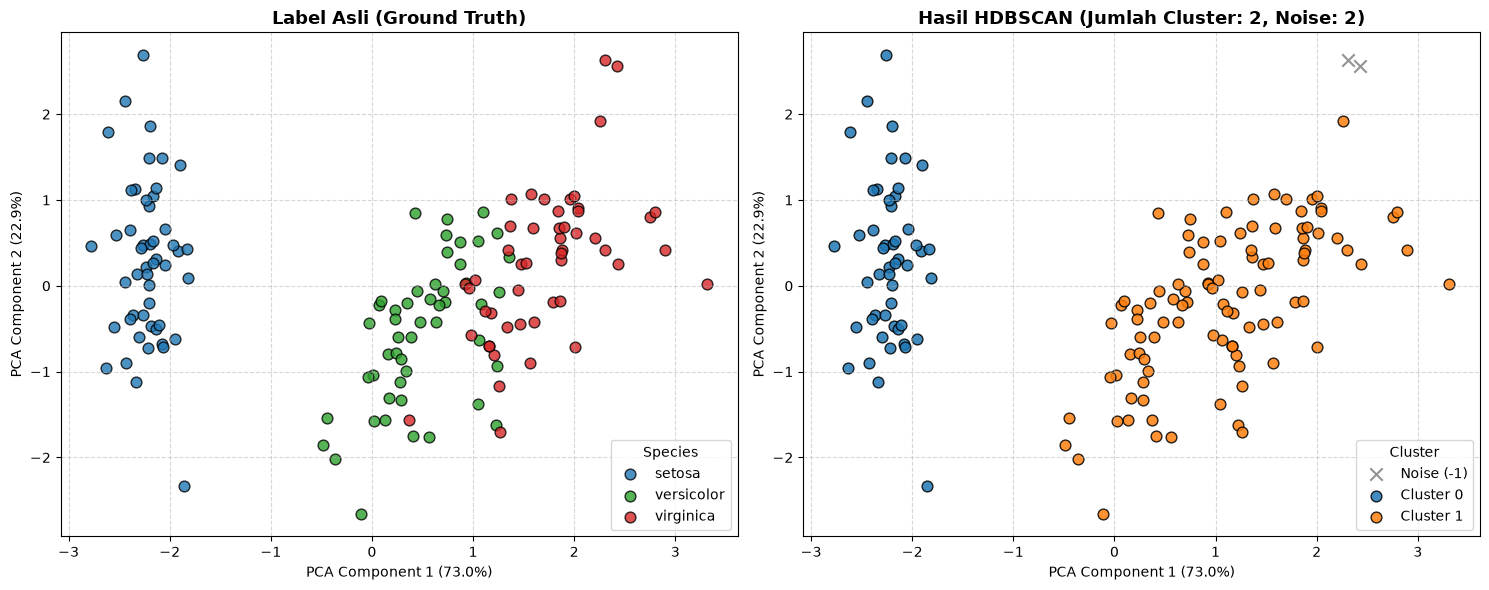

In [8]:
# Visualisasi 2D: Label Asli vs Hasil Cluster HDBSCAN
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Ground Truth
species_palette = {'setosa': '#1f77b4', 'versicolor': '#2ca02c', 'virginica': '#d62728'}
for sp, color in species_palette.items():
    subset = df[df['species'] == sp]
    axes[0].scatter(subset['PCA1'], subset['PCA2'], c=color, label=sp, alpha=0.8, edgecolors='k', s=60)
axes[0].set_title('Label Asli (Ground Truth)', fontsize=13, fontweight='bold')
axes[0].set_xlabel(f'PCA Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PCA Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend(title='Species')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: HDBSCAN Clustering
cluster_palette = {-1: 'gray', 0: '#1f77b4', 1: '#ff7f0e'}
cluster_names = {-1: 'Noise (-1)', 0: 'Cluster 0', 1: 'Cluster 1'}

for cl, color in cluster_palette.items():
    subset = df[df['Cluster'] == cl]
    marker = 'x' if cl == -1 else 'o'
    axes[1].scatter(subset['PCA1'], subset['PCA2'], c=color, label=cluster_names[cl], 
                    alpha=0.85, edgecolors='none' if cl == -1 else 'k', marker=marker, s=80 if cl == -1 else 60)
axes[1].set_title(f'Hasil HDBSCAN (Jumlah Cluster: {n_clusters}, Noise: {n_noise})', fontsize=13, fontweight='bold')
axes[1].set_xlabel(f'PCA Component 1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PCA Component 2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].legend(title='Cluster')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


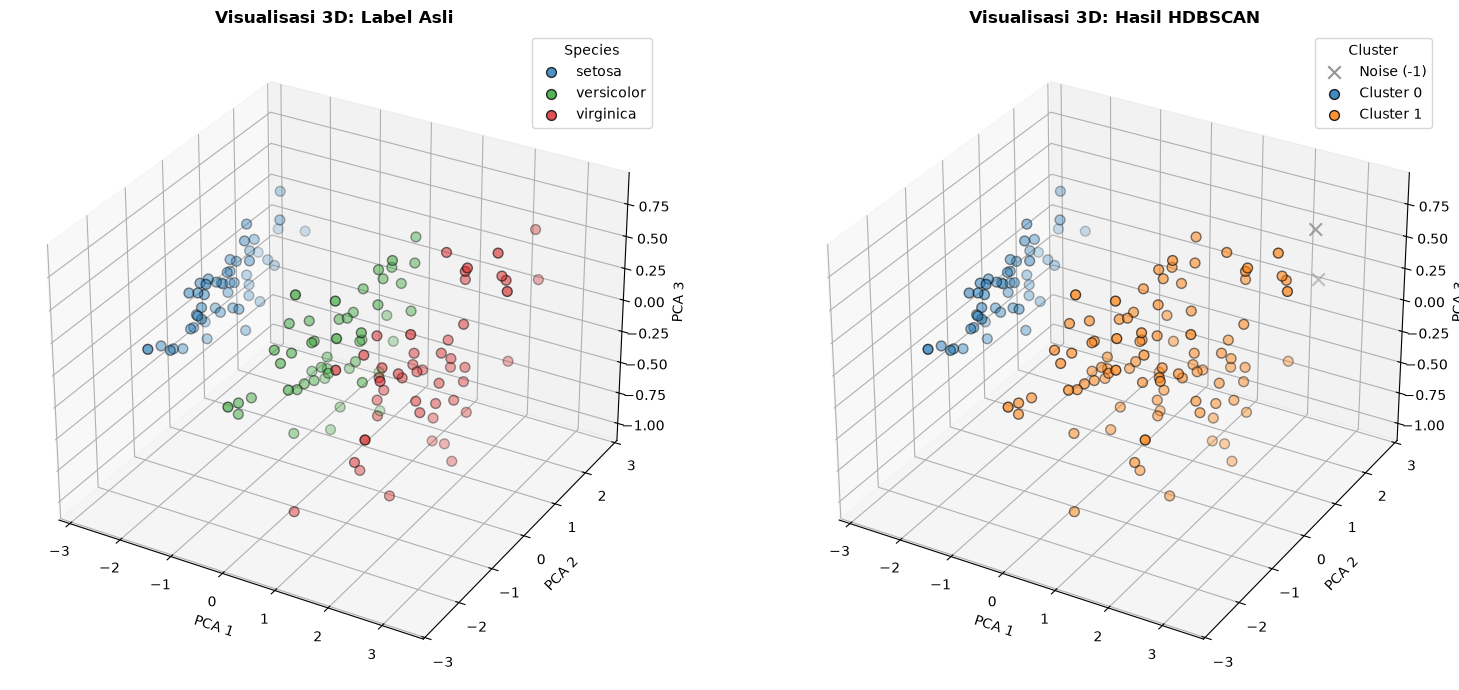

In [9]:
# Visualisasi 3D Interaktif / Matplotlib 3D
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(16, 7))

# 3D Ground Truth
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
for sp, color in species_palette.items():
    subset = df[df['species'] == sp]
    ax1.scatter(subset['PCA1'], subset['PCA2'], subset['PCA3'], c=color, label=sp, s=50, edgecolors='k', alpha=0.8)
ax1.set_title('Visualisasi 3D: Label Asli', fontsize=12, fontweight='bold')
ax1.set_xlabel('PCA 1')
ax1.set_ylabel('PCA 2')
ax1.set_zlabel('PCA 3')
ax1.legend(title='Species')

# 3D HDBSCAN
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
for cl, color in cluster_palette.items():
    subset = df[df['Cluster'] == cl]
    marker = 'x' if cl == -1 else 'o'
    ax2.scatter(subset['PCA1'], subset['PCA2'], subset['PCA3'], c=color, label=cluster_names[cl], 
                s=80 if cl == -1 else 50, edgecolors='none' if cl == -1 else 'k', marker=marker, alpha=0.85)
ax2.set_title('Visualisasi 3D: Hasil HDBSCAN', fontsize=12, fontweight='bold')
ax2.set_xlabel('PCA 1')
ax2.set_ylabel('PCA 2')
ax2.set_zlabel('PCA 3')
ax2.legend(title='Cluster')

plt.tight_layout()
plt.show()


# Analisis Hasil Clustering HDBSCAN

### 1. Ringkasan Hasil:
- **Jumlah Cluster Terbentuk:** **2 Cluster** (Cluster 0 dan Cluster 1).
- **Banyaknya Noise:** **2 sampel** (diberi label `-1`, berasal dari spesies *virginica*).

---

### 2. Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset Iris?

**Jawaban:**  
Hasil clustering HDBSCAN **hanya sebagian sesuai** dengan label asli dataset Iris:

1. **Pemisahan Sempurna pada *Setosa* (Cluster 0):**
   - Seluruh 50 sampel dari spesies *Iris-setosa* secara sempurna dikelompokkan ke dalam **Cluster 0** tanpa ada kesalahan (100% homogen / terisolasi dengan sangat baik).
   - Hal ini karena spesies *setosa* memiliki jarak spasial dan densitas yang terpisah secara tegas (*linearly and density separable*) dari kedua spesies lainnya.

2. **Penggabungan *Versicolor* dan *Virginica* (Cluster 1):**
   - Spesies *Iris-versicolor* (50 sampel) dan sebagian besar *Iris-virginica* (48 sampel) digabungkan oleh HDBSCAN ke dalam satu kelompok besar (**Cluster 1**).
   - **Alasan Teknis HDBSCAN:**  
     HDBSCAN bekerja berdasarkan kerapatan spasial (*density-based*). Pada ruang fitur Iris, sebaran titik data *versicolor* dan *virginica* saling tumpang tindih (*overlapping*) dan membentuk daerah berkepadatan kontinu (*continuous high-density region*). Tidak ada lembah kerapatan rendah (*density drop*) yang cukup signifikan di antara keduanya untuk memisahkan mereka menjadi dua klaster independen.

3. **Deteksi Noise / Outlier (-1):**
   - HDBSCAN mendeteksi **2 titik data** sebagai noise (keduanya dari kelas *virginica*). Titik-titik ini berada di wilayah marjinal berdensitas rendah menjauhi inti sebaran data.

### 3. Kesimpulan:
HDBSCAN secara akurat menangkap struktur kerapatan alami (*natural density structure*) data Iris (yang memang secara geometris terbagi atas 2 komponen densitas utama), meskipun secara taksonomi biologis dataset Iris memiliki 3 kelas target. Ini menunjukkan sifat khas density-based clustering: tidak memaksakan pemisahan jika tidak ditemukan batas densitas yang nyata.
